# BÁO CÁO THỰC HÀNH CNN
## Phân loại hình ảnh phương tiện giao thông: ô tô và xe máy

**Học phần:** PRN501 · **Ngày biên soạn:** 07/11/2026  
**Phương pháp:** CNN huấn luyện từ đầu bằng Keras 3 · **Đầu ra:** xác suất và nhãn của hai lớp

> **Câu hỏi nghiên cứu:** Một mạng tích chập nhỏ có thể học cách phân biệt ảnh ô tô và xe máy trong hai nhóm ảnh của Caltech-101 đến mức nào?

Báo cáo đi từ lý thuyết tích chập đến chuẩn bị dữ liệu, xây dựng mô hình, huấn luyện, chọn checkpoint bằng validation và đánh giá trên test. Code có chú thích tiếng Việt, hình ảnh minh họa, biểu đồ và nhận xét dựa trên kết quả thực chạy.

Đây là bài **phân loại một ảnh vào một trong hai lớp**, không phải phát hiện hay đếm nhiều phương tiện trong ảnh. Dữ liệu gồm ảnh đối tượng, chưa đại diện đầy đủ cho cảnh giao thông Việt Nam.

## 1. Mục tiêu, bố cục và cách chạy

| Giai đoạn | Nội dung |
|---|---|
| Hiểu thuật toán | Convolution, ReLU, pooling, sigmoid và binary cross-entropy |
| Chuẩn bị dữ liệu | Đọc ảnh thật, kiểm tra lỗi/trùng, thống kê lớp, chia train/validation/test |
| Xây dựng và học | CNN 3 khối, augmentation, Adam, class weights, early stopping |
| Đánh giá | Accuracy, balanced accuracy, precision/recall/F1, confusion matrix, ảnh sai |
| Sử dụng lại | Lưu/nạp `.keras`, dự đoán ảnh riêng và kiểm tra preprocessing |

**Cách chạy:** giải nén toàn bộ gói báo cáo, mở notebook trong thư mục đó bằng VS Code/Jupyter, rồi chọn **Run All**. Python 3.10 trở lên được khuyến nghị. Có thể chạy trên Colab; tải lên `data/vehicle_images.zip` đúng đường dẫn hoặc để notebook tải dữ liệu khi thiếu. CPU có thể chạy bài này; GPU không bắt buộc.

Bài dùng **Keras 3 với backend PyTorch** với API `Conv2D`, `model.fit`, callbacks và định dạng lưu mô hình `.keras`. Phải đặt backend **trước khi import Keras**; nếu đã import Keras với backend khác, hãy restart kernel. Không cần TensorFlow, tài khoản Kaggle hoặc khóa API. Bỏ dấu `#` ở ô cài đặt chỉ khi môi trường thiếu thư viện.

In [1]:
# Cài một lần nếu thiếu, sau đó restart kernel:
# %pip install "keras>=3" torch numpy matplotlib pillow scikit-learn h5py

import os
os.environ['KERAS_BACKEND']='torch'  # Đặt trước import keras.
os.environ.setdefault('CUDA_VISIBLE_DEVICES','')  # Thực nghiệm mặc định trên CPU.
from pathlib import Path
import io, json, csv, random, hashlib, zipfile, tarfile, urllib.request, html, platform
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
import torch
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score)
from IPython.display import display, HTML

SEED=42
keras.utils.set_random_seed(SEED)
torch.set_num_threads(2)
plt.rcParams.update({'figure.dpi':130,'font.family':'DejaVu Sans',
                     'axes.spines.top':False,'axes.spines.right':False})

def table(headers,rows):
    def td(x):return html.escape(str(x))
    head=''.join('<th>'+td(x)+'</th>' for x in headers)
    body=''.join('<tr>'+''.join('<td>'+td(x)+'</td>' for x in r)+'</tr>' for r in rows)
    display(HTML('<table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'))

print('Python:',platform.python_version(),'| NumPy:',np.__version__)
print('Keras:',keras.__version__,'| Backend:',keras.backend.backend(),'| PyTorch:',torch.__version__)

Python: 3.13.1 | NumPy: 2.5.3
Keras: 3.15.1 | Backend: torch | PyTorch: 2.14.1+cpu


## 2. Phát biểu bài toán và quy ước nhãn

Đầu vào là một ảnh RGB chứa phương tiện chính; đầu ra là xác suất $p=P(y=1\mid x)$ và nhãn dự đoán.

| ID | Nhãn báo cáo | Nhóm ảnh gốc |
|---|---|---|
| 0 | Ô tô | `car_side` |
| 1 | Xe máy | `Motorbikes` |

Với ngưỡng **0,5 cố định trước khi đánh giá**, nếu $p\geq0,5$ thì dự đoán xe máy, ngược lại là ô tô. Trong báo cáo, **lớp dương là xe máy**; precision/recall theo lớp cũng được trình bày để không che khuất kết quả lớp ô tô ít mẫu hơn.

Ảnh nhiều loại xe, xe bị che khuất nặng hoặc ảnh không có xe nằm ngoài phạm vi hai nhãn huấn luyện. Sigmoid vẫn cho ra một số trên ảnh ngoài phạm vi, nên không xem xác suất lớn là bảo đảm nhận dạng đúng.

## 3. Cơ sở lý thuyết CNN

### 3.1. Tích chập và bộ lọc

Một kernel nhỏ trượt trên ảnh, dùng chung trọng số giữa các vị trí. Với stride 1, đầu ra tại một vị trí được tính bằng tổng tích các giá trị trong vùng ảnh và trọng số kernel, cộng bias. Trong thư viện học sâu, thao tác thường được gọi là convolution dù thực hiện **cross-correlation** không lật kernel:

$$z_{i,j,k}=b_k+\sum_{u,v,c}x_{i+u,j+v,c}w_{u,v,c,k}.$$

Với kernel $K$, padding $P$, stride $S$, kích thước không gian đầu ra là
$$H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1.$$

CNN có thể học đặc trưng như cạnh, kết cấu, hình khối và tổ hợp của chúng. Ta không gán thủ công một filter chuyên nhận bánh xe hay tay lái; đặc trưng được điều chỉnh từ dữ liệu và loss.

### 3.2. ReLU, pooling và đầu ra

ReLU tính $\max(0,z)$ để thêm phi tuyến. MaxPooling $2\times2$ lấy giá trị lớn nhất trong từng cửa sổ, làm giảm chiều không gian. GlobalAveragePooling lấy trung bình từng feature map; Dropout bỏ ngẫu nhiên một phần kích hoạt trong lúc train nhằm giảm phụ thuộc quá mức vào một số đặc trưng.

Sigmoid $\sigma(z)=1/(1+e^{-z})$ tạo xác suất nhị phân. Binary cross-entropy của một mẫu là
$$\ell=-[y\log p+(1-y)\log(1-p)].$$

Adam dùng gradient để cập nhật trọng số. Quá trình này khác với ví dụ tính tay bên dưới, nơi kernel được chọn sẵn chỉ để giải thích phép toán.

In [2]:
# Ví dụ phép tính nhỏ, không phải filter đã học hay kết quả phân loại ảnh.
patch=np.array([[1,0,2],[2,1,0],[0,1,3]],dtype=float)
kernel=np.array([[1,0,-1],[1,0,-1],[1,0,-1]],dtype=float)
products=patch*kernel
z=products.sum()
pooled_example=np.array([[1,3],[2,0]],dtype=float).max()
table(['Đại lượng','Giá trị'],[
    ('Ảnh con 3×3',patch.tolist()),('Kernel 3×3',kernel.tolist()),
    ('Nhân từng phần tử',products.tolist()),('Tổng + bias 0',z),
    ('Sau ReLU',max(0,z)),('MaxPooling trên [[1,3],[2,0]]',pooled_example)])
assert z==-2 and pooled_example==3

Đại lượng,Giá trị
Ảnh con 3×3,"[[1.0, 0.0, 2.0], [2.0, 1.0, 0.0], [0.0, 1.0, 3.0]]"
Kernel 3×3,"[[1.0, 0.0, -1.0], [1.0, 0.0, -1.0], [1.0, 0.0, -1.0]]"
Nhân từng phần tử,"[[1.0, 0.0, -2.0], [2.0, 0.0, -0.0], [0.0, 0.0, -3.0]]"
Tổng + bias 0,-2.0
Sau ReLU,0
"MaxPooling trên [[1,3],[2,0]]",3.0


## 4. Nguồn dữ liệu và cấu hình thực nghiệm

Sử dụng hai thư mục **`car_side` và `Motorbikes` của Caltech-101**, do Fei-Fei Li, Marco Andreetto, Marc'Aurelio Ranzato và Pietro Perona công bố. Nguồn chính thức: [CaltechDATA, DOI 10.22002/D1.20086](https://data.caltech.edu/records/mzrjq-6wc02).

Gói đi kèm chỉ giữ nguyên các ảnh JPEG thuộc hai nhóm này, không thêm ảnh vẽ hay ảnh sinh. Nếu cần tải lại, code tải archive từ kho chính thức hoặc [bản sao Hugging Face](https://huggingface.co/datasets/HuggingFaceM4/Caltech-101), đối chiếu **MD5 `3138e1922a9193bfa496528edbbc45d0`** do CaltechDATA công bố, rồi chọn hai thư mục cần dùng. MD5 ở đây nhằm đối chiếu archive, không phải chứng minh quyền sử dụng hay kiểm tra an toàn bảo mật.

Ảnh được resize có giữ tỉ lệ và thêm viền đệm về **64×64 RGB**. Chọn kích thước này để chạy thực nghiệm nhỏ trên CPU; có thể thử ảnh lớn hơn trong một thực nghiệm mới, sử dụng validation để lựa chọn cấu hình. Không điều chỉnh cấu hình sau khi nhìn kết quả test của lần chạy này.

In [3]:
ROOT=Path.cwd()
# Nếu mở notebook từ gốc E:/FSB thay vì thư mục báo cáo, tự tìm gói đã có.
candidate=ROOT/'PRN501'/'CNN_XeMay_OTo_Report'
if not (ROOT/'data'/'vehicle_images.zip').exists() and (candidate/'data'/'vehicle_images.zip').exists():
    ROOT=candidate
DATA_ZIP=ROOT/'data'/'vehicle_images.zip'
ARTIFACTS=ROOT/'artifacts'
ARTIFACTS.mkdir(parents=True,exist_ok=True)
IMG_SIZE=(64,64)
BATCH_SIZE=32
MAX_EPOCHS=30
LEARNING_RATE=1e-3
THRESHOLD=0.5
CLASS_NAMES=['Ô tô','Xe máy']
EXPECTED_MD5='3138e1922a9193bfa496528edbbc45d0'

def download_vehicle_data(destination):
    """Tải archive có kiểm tra checksum, chỉ chép hai nhóm ảnh vào zip mới."""
    destination.parent.mkdir(parents=True,exist_ok=True)
    archive=destination.parent/'caltech-101.zip'
    urls=[
      'https://data.caltech.edu/records/mzrjq-6wc02/files/caltech-101.zip?download=1',
      'https://huggingface.co/datasets/HuggingFaceM4/Caltech-101/resolve/main/caltech-101.zip?download=true']
    if not archive.exists() or hashlib.md5(archive.read_bytes()).hexdigest()!=EXPECTED_MD5:
        for url in urls:
            try:
                urllib.request.urlretrieve(url,archive)
                if hashlib.md5(archive.read_bytes()).hexdigest()!=EXPECTED_MD5:
                    raise ValueError('Checksum archive không đúng.')
                break
            except Exception as error:
                print('Không tải được từ nguồn này:',type(error).__name__)
        else:
            raise RuntimeError('Không tải được dữ liệu. Đặt data/vehicle_images.zip từ gói báo cáo vào thư mục notebook.')
    with zipfile.ZipFile(archive) as original:
        candidates=[n for n in original.namelist() if Path(n).name=='101_ObjectCategories.tar.gz']
        if len(candidates)!=1:raise ValueError('Không tìm thấy đúng một archive ảnh.')
        with original.open(candidates[0]) as stream, tarfile.open(fileobj=stream,mode='r|gz') as tar:
            with zipfile.ZipFile(destination,'w',compression=zipfile.ZIP_DEFLATED) as selected:
                for member in tar:
                    parts=Path(member.name).parts
                    if member.isfile() and len(parts)>=2 and parts[-2] in ('car_side','Motorbikes') and parts[-1].lower().endswith('.jpg'):
                        selected.writestr(parts[-2]+'/'+parts[-1],tar.extractfile(member).read())
    print('Đã chuẩn bị:',destination)

if not DATA_ZIP.exists():download_vehicle_data(DATA_ZIP)
print('Gói ảnh:',DATA_ZIP)
print('SHA-256 gói ảnh:',hashlib.sha256(DATA_ZIP.read_bytes()).hexdigest())

Không tải được từ nguồn này: HTTPError
Đã chuẩn bị: C:\FSB\data\vehicle_images.zip
Gói ảnh: C:\FSB\data\vehicle_images.zip
SHA-256 gói ảnh: d17ae27f2c75809235939061f45b8330dd2ed65cd56c2ff20f74fa0977f0db71


## 5. Đọc, kiểm tra và loại ảnh trùng trước khi chia tập

Quy trình đọc: ảnh bytes → kiểm tra ảnh → sửa hướng EXIF → RGB → resize có đệm. Ảnh lỗi được ghi vào danh sách, không âm thầm bỏ qua trong quá trình train. Hai ảnh có cùng hash của **ma trận RGB sau tiền xử lý** được giữ một bản trước khi chia tập; trùng nội dung nhưng khác nhãn sẽ làm code dừng để kiểm tra.

Cách này loại ảnh giống hệt theo biểu diễn đầu vào, **không bảo đảm phát hiện hết ảnh gần trùng, cùng phương tiện hay cùng cảnh chụp**. Tập test là holdout theo ảnh, không phải kiểm thử độc lập theo người chụp/địa điểm/xe.

**Lưu ý thiên lệch dữ liệu:** trong các ảnh minh họa, ô tô chủ yếu có vẻ là ảnh xám, trong khi xe máy có nhiều ảnh màu và nền đơn giản. CNN có thể khai thác màu/nền hoặc dấu hiệu nguồn ảnh thay vì chỉ hình dạng phương tiện. Cần một thực nghiệm đối chứng trên dữ liệu độc lập, chẳng hạn đưa cả hai lớp về ảnh xám và thay đổi nền, trước khi kết luận mô hình học đặc trưng phương tiện bền vững.

In [4]:
def prepare_image(image):
    # Giữ tỉ lệ hình học, tránh kéo xe dài/ngắn không tự nhiên.
    image=ImageOps.exif_transpose(image).convert('RGB')
    image=ImageOps.pad(image,IMG_SIZE,method=Image.Resampling.BILINEAR,color=(127,127,127))
    return np.asarray(image,dtype=np.uint8)

images,labels,records=[],[],[]
seen={}
duplicates,broken=[],[]
raw_counts={name:0 for name in CLASS_NAMES}
with zipfile.ZipFile(DATA_ZIP) as archive:
    for name in sorted(archive.namelist()):
        parts=Path(name).parts
        if len(parts)!=2 or parts[0] not in ('car_side','Motorbikes') or not name.lower().endswith('.jpg'):continue
        label=0 if parts[0]=='car_side' else 1
        raw_counts[CLASS_NAMES[label]]+=1
        try:
            data=archive.read(name)
            with Image.open(io.BytesIO(data)) as image:
                image.load()
                array=prepare_image(image)
        except Exception as error:
            broken.append((name,str(error)));continue
        digest=hashlib.sha256(array.tobytes()).hexdigest()
        if digest in seen:
            if seen[digest][1]!=label:raise ValueError('Ảnh trùng nhưng khác nhãn: '+name)
            duplicates.append((name,seen[digest][0]));continue
        seen[digest]=(name,label)
        images.append(array);labels.append(label)
        records.append({'file':name,'label':label,'pixel_sha256':digest})

X=np.stack(images)
y=np.array(labels,dtype=np.int64)
assert X.shape[1:]==(64,64,3) and set(y.tolist())=={0,1}
table(['Lớp','Ảnh trong archive','Sau kiểm tra/loại trùng'],
      [(name,raw_counts[name],int((y==i).sum())) for i,name in enumerate(CLASS_NAMES)])
print('Ảnh lỗi:',len(broken),'| Bản trùng được bỏ:',len(duplicates))
print('X:',X.shape,X.dtype,'| Miền pixel:',int(X.min()),'→',int(X.max()))
if broken:table(['Ảnh lỗi','Nguyên nhân'],broken)
if duplicates:table(['Ảnh bị bỏ','Giống ảnh'],duplicates[:10])

Lớp,Ảnh trong archive,Sau kiểm tra/loại trùng
Ô tô,123,123
Xe máy,798,798


Ảnh lỗi: 0 | Bản trùng được bỏ: 0
X: (921, 64, 64, 3) uint8 | Miền pixel: 0 → 255


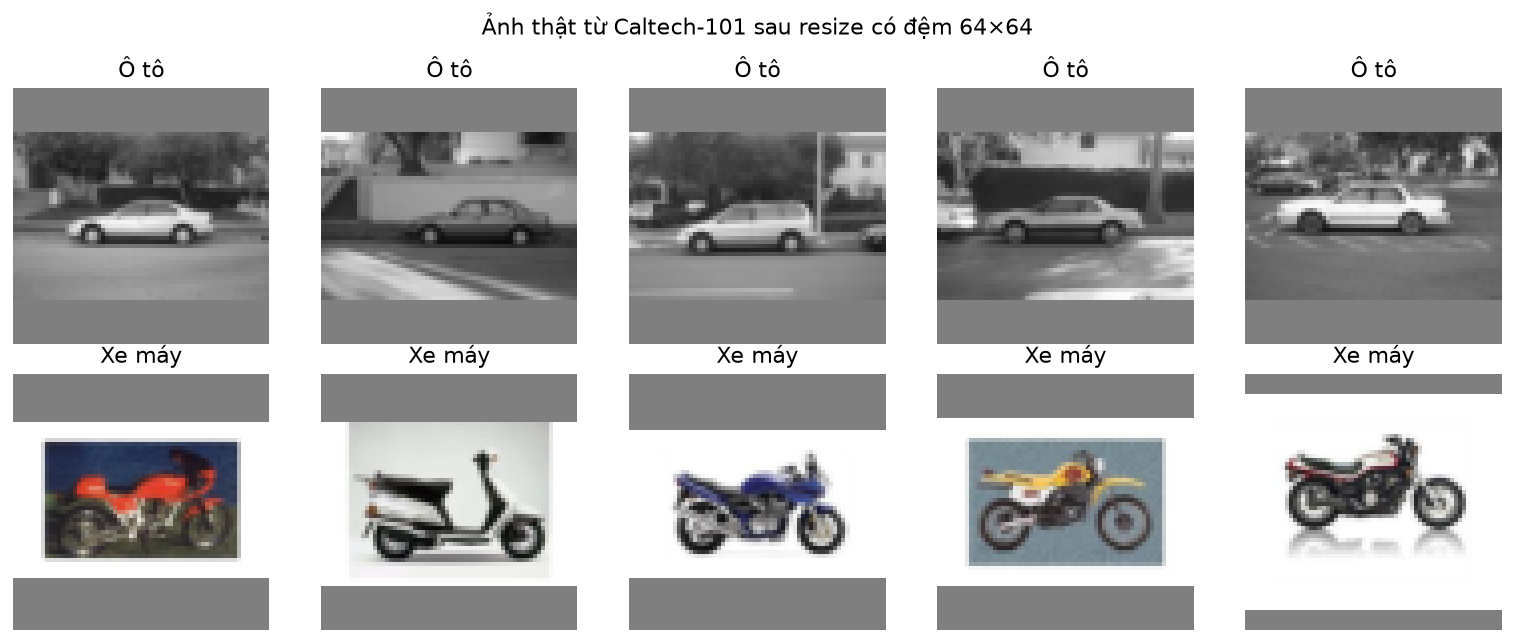

In [5]:
fig,axes=plt.subplots(2,5,figsize=(12,5))
rng=np.random.default_rng(SEED)
for label in range(2):
    selected=rng.choice(np.flatnonzero(y==label),5,replace=False)
    for ax,idx in zip(axes[label],selected):
        ax.imshow(X[idx]);ax.set_title(CLASS_NAMES[label]);ax.axis('off')
fig.suptitle('Ảnh thật từ Caltech-101 sau resize có đệm 64×64')
plt.tight_layout();plt.show()

## 6. Chia train / validation / test và kiểm tra rò rỉ

Chia phân tầng theo lớp: khoảng **70% train, 15% validation, 15% test**; số nguyên có thể lệch nhẹ vì làm tròn. Train dùng cập nhật trọng số, validation chọn epoch và giảm learning rate, test giữ riêng đến sau khi huấn luyện và khôi phục checkpoint.

Đặt seed giúp lặp lại phép chia. Ba tập không trùng chỉ số hoặc hash pixel. **Augmentation chỉ áp dụng trên train sau khi chia tập.** Không tạo nhiều phiên bản một ảnh rồi chia chúng sang các tập khác nhau.

Hai lớp có thể mất cân bằng. Ta không bỏ bớt lớp lớn; dùng class weights tính **chỉ trên train**: $w_c=N_{train}/(2N_c)$. Vì loss train được nhân trọng số còn validation loss không nhân, hai đường loss không hoàn toàn cùng cách tính. Accuracy train được dùng ở dạng không trọng số.

Tập,Ô tô (0),Xe máy (1),Tổng
Train,86,558,644
Validation,18,120,138
Test,19,120,139


Class weights từ train: {0: 3.744186046511628, 1: 0.5770609318996416}


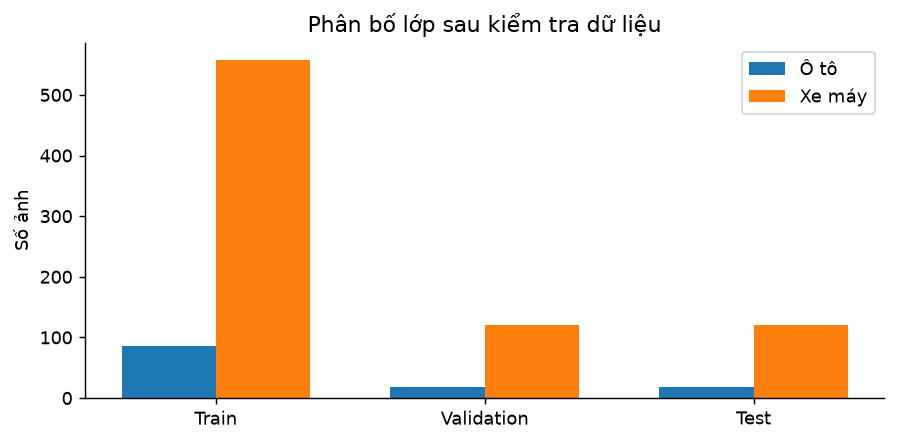

In [6]:
indices=np.arange(len(y))
trainval_idx,test_idx=train_test_split(indices,test_size=.15,random_state=SEED,stratify=y)
train_idx,val_idx=train_test_split(trainval_idx,test_size=.15/.85,random_state=SEED,stratify=y[trainval_idx])
splits={'Train':train_idx,'Validation':val_idx,'Test':test_idx}
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)
hash_sets=[{records[int(i)]['pixel_sha256'] for i in idx} for idx in splits.values()]
assert all(hash_sets[i].isdisjoint(hash_sets[j]) for i in range(3) for j in range(i+1,3))
assert sum(map(len,splits.values()))==len(y)
table(['Tập','Ô tô (0)','Xe máy (1)','Tổng'],
      [(name,int((y[idx]==0).sum()),int((y[idx]==1).sum()),len(idx)) for name,idx in splits.items()])
X_train,X_val,X_test=X[train_idx],X[val_idx],X[test_idx]
y_train,y_val,y_test=y[train_idx],y[val_idx],y[test_idx]
class_weight={c:len(y_train)/(2*int((y_train==c).sum())) for c in range(2)}
print('Class weights từ train:',class_weight)
for split,idx in splits.items():
    for i in idx:records[int(i)]['split']=split
with (ARTIFACTS/'split_manifest.csv').open('w',newline='',encoding='utf-8-sig') as f:
    writer=csv.DictWriter(f,fieldnames=['file','label','pixel_sha256','split'])
    writer.writeheader();writer.writerows(records)

fig,ax=plt.subplots(figsize=(7,3.5))
positions=np.arange(3)
for c,name in enumerate(CLASS_NAMES):
    ax.bar(positions+(c-.5)*.35,[int((y[idx]==c).sum()) for idx in splits.values()],width=.35,label=name)
ax.set_xticks(positions,list(splits));ax.set_ylabel('Số ảnh');ax.set_title('Phân bố lớp sau kiểm tra dữ liệu')
ax.legend();plt.tight_layout();plt.show()

## 7. Tăng cường dữ liệu và chuẩn hóa

Trong khi train, lật ngang và xoay nhẹ giúp mô hình thấy các biến thể hợp lý. Không lật dọc vì phương tiện lộn ngược không đại diện cách chụp thông thường. Các lớp augmentation tự tắt ở `training=False`, dùng cho validation, test và dự đoán.

`Rescaling(1/255)` nằm **trong mô hình**: ảnh vào vẫn có pixel 0–255; không chia thêm 255 ở ngoài. Xử lý resize có đệm được dùng thống nhất lúc train và suy luận. Bốn ảnh biến thể dưới đây chỉ để minh họa, không được đưa vào test.

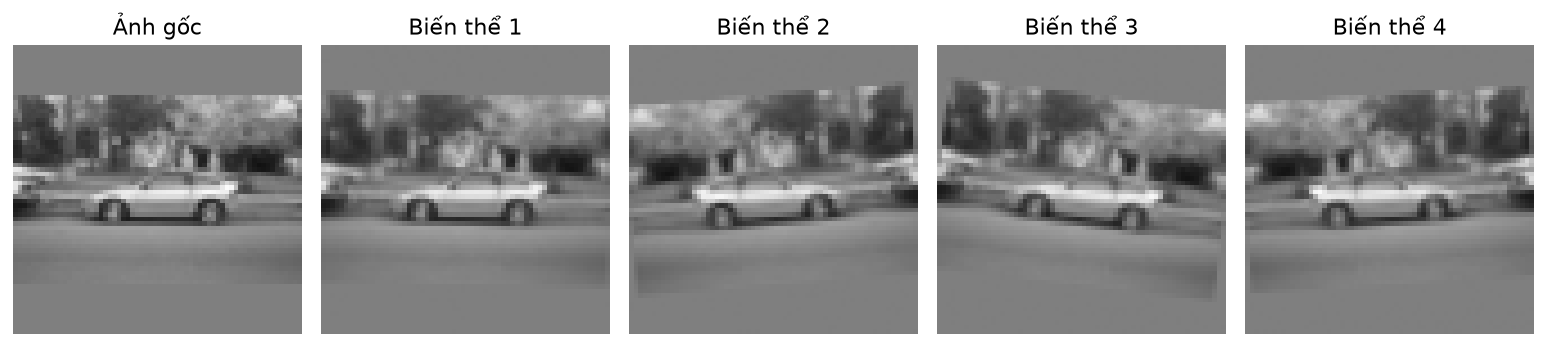

In [7]:
augmentation=keras.Sequential([
    layers.RandomFlip('horizontal',seed=SEED),
    layers.RandomRotation(.03,fill_mode='constant',fill_value=127,seed=SEED+1),
],name='augmentation')
augmentation_input=X_train[np.flatnonzero(y_train==0)[0]:np.flatnonzero(y_train==0)[0]+1].astype('float32')
fig,axes=plt.subplots(1,5,figsize=(12,3))
axes[0].imshow(augmentation_input[0].astype('uint8'));axes[0].set_title('Ảnh gốc');axes[0].axis('off')
for k,ax in enumerate(axes[1:]):
    variant=keras.ops.convert_to_numpy(augmentation(augmentation_input,training=True))[0]
    ax.imshow(np.clip(variant,0,255).astype('uint8'));ax.set_title('Biến thể '+str(k+1));ax.axis('off')
plt.tight_layout();plt.show()

## 8. Xây dựng CNN từ đầu

| Thành phần | Kích thước đầu ra, bỏ chiều batch | Vai trò |
|---|---|---|
| Input + augmentation + rescaling | 64×64×3 | Ảnh RGB và tiền xử lý |
| Conv 3×3, 16 filter, same + ReLU | 64×64×16 | Đặc trưng mức đầu |
| MaxPool 2×2 | 32×32×16 | Giảm chiều không gian |
| Conv 3×3, 32 filter + ReLU + MaxPool | 16×16×32 | Tổ hợp đặc trưng |
| Conv 3×3, 64 filter + ReLU + MaxPool | 8×8×64 | Biểu diễn sâu hơn |
| GlobalAveragePooling | 64 | Trung bình từng feature map |
| Dense 32, ReLU + Dropout 0,3 | 32 | Học kết hợp đặc trưng |
| Dense 1, sigmoid | 1 | $P(\mathrm{xe\ máy}\mid x)$ |

Số tham số của một Conv2D có bias: $(K_hK_wC_{in}+1)C_{out}$. Ví dụ Conv đầu có $(3\times3\times3+1)\times16=448$ tham số. GlobalAveragePooling không có tham số; với đầu ra này, nó giảm số đầu vào của Dense từ $8\times8\times64=4096$ xuống 64 so với Flatten.

Mạng không dùng backbone pretrained hay nhận dạng vật thể có sẵn. CNN được khởi tạo ngẫu nhiên và học trên tập train của bài. Đây là lựa chọn để hiểu thuật toán; mô hình pretrained là hướng mở rộng cho dữ liệu nhỏ.

In [8]:
# Đặt seed lại để phần xem augmentation không làm đổi khởi tạo mô hình.
keras.utils.set_random_seed(SEED)
model=keras.Sequential([
    keras.Input(shape=IMG_SIZE+(3,),name='image_rgb'),
    augmentation,
    layers.Rescaling(1./255,name='rescale'),
    layers.Conv2D(16,3,padding='same',activation='relu',name='conv_1'),
    layers.MaxPooling2D(name='pool_1'),
    layers.Conv2D(32,3,padding='same',activation='relu',name='conv_2'),
    layers.MaxPooling2D(name='pool_2'),
    layers.Conv2D(64,3,padding='same',activation='relu',name='conv_3'),
    layers.MaxPooling2D(name='pool_3'),
    layers.GlobalAveragePooling2D(name='global_average'),
    layers.Dense(32,activation='relu',name='dense_features'),
    layers.Dropout(.3,seed=SEED,name='dropout'),
    layers.Dense(1,activation='sigmoid',name='prob_motorbike'),
],name='cnn_car_motorbike')
model.summary()
assert model.get_layer('conv_1').count_params()==448
assert model.output_shape==(None,1)
print('Tổng tham số:',model.count_params())

Model: "cnn_car_motorbike"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)            │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescale (Rescaling)                  │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_1 (Conv2D)                      │ (None, 64, 64, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_1 (MaxPooling2D)                │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_2 (Conv2D)                      │ (None, 32, 32, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_2 (MaxPooling2D)                │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_3 (Conv2D)                      │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_3 (MaxPooling2D)                │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average                       │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_features (Dense)               │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ prob_motorbike (Dense)               │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,697 (100.38 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)

Tổng tham số: 25697


## 9. Compile và huấn luyện

Dùng Adam, learning rate ban đầu $10^{-3}$, binary cross-entropy và batch size 32. Tối đa 30 epoch; không cam kết một mức accuracy trước khi chạy.

- `ModelCheckpoint`: lưu mô hình ở epoch có **validation loss thấp nhất**.
- `EarlyStopping`: dừng khi validation loss không cải thiện qua 6 epoch, khôi phục trọng số tốt nhất.
- `ReduceLROnPlateau`: giảm learning rate một nửa nếu validation loss không cải thiện qua 3 epoch.

Mỗi epoch duyệt hết train; không đặt `steps_per_epoch` bằng phép chia lấy phần nguyên làm mất batch cuối. **Test không được truyền vào `fit`**, không chọn epoch/ngưỡng bằng test. Sau train, nạp lại file checkpoint để chắc chắn mô hình được đánh giá là mô hình đã chọn bằng validation.

In [9]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss='binary_crossentropy',metrics=[keras.metrics.BinaryAccuracy(name='accuracy',threshold=THRESHOLD)])
BEST_PATH=ARTIFACTS/'cnn_car_motorbike.keras'
callbacks=[
    keras.callbacks.ModelCheckpoint(str(BEST_PATH),monitor='val_loss',save_best_only=True,verbose=0),
    keras.callbacks.EarlyStopping(monitor='val_loss',patience=6,restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.5,patience=3,min_lr=1e-5),
]
history=model.fit(X_train,y_train.astype('float32'),validation_data=(X_val,y_val.astype('float32')),
                  epochs=MAX_EPOCHS,batch_size=BATCH_SIZE,shuffle=True,
                  class_weight=class_weight,callbacks=callbacks,verbose=2)
model=keras.models.load_model(BEST_PATH)
h=history.history
best_epoch=int(np.argmin(h['val_loss']))+1
print('Epoch đã chạy:',len(h['loss']),'| Epoch val_loss nhỏ nhất:',best_epoch)
with (ARTIFACTS/'history.json').open('w',encoding='utf-8') as f:
    json.dump({k:[float(x) for x in v] for k,v in h.items()},f,ensure_ascii=False,indent=2)

Epoch 1/30
21/21 - 3s - 122ms/step - accuracy: 0.8478 - loss: 0.6878 - val_accuracy: 0.8696 - val_loss: 0.5939 - learning_rate: 0.0010
Epoch 2/30
21/21 - 2s - 114ms/step - accuracy: 0.8571 - loss: 0.6754 - val_accuracy: 0.8696 - val_loss: 0.5802 - learning_rate: 0.0010
Epoch 3/30
21/21 - 2s - 118ms/step - accuracy: 0.8680 - loss: 0.6648 - val_accuracy: 0.8696 - val_loss: 0.5569 - learning_rate: 0.0010
Epoch 4/30
21/21 - 3s - 124ms/step - accuracy: 0.8602 - loss: 0.6335 - val_accuracy: 0.8696 - val_loss: 0.4420 - learning_rate: 0.0010
Epoch 5/30
21/21 - 3s - 128ms/step - accuracy: 0.8789 - loss: 0.5676 - val_accuracy: 0.8406 - val_loss: 0.5561 - learning_rate: 0.0010
Epoch 6/30
21/21 - 2s - 115ms/step - accuracy: 0.8649 - loss: 0.4498 - val_accuracy: 0.8696 - val_loss: 0.2507 - learning_rate: 0.0010
Epoch 7/30
21/21 - 3s - 124ms/step - accuracy: 0.8711 - loss: 0.3670 - val_accuracy: 0.9420 - val_loss: 0.1946 - learning_rate: 0.0010
Epoch 8/30
21/21 - 3s - 125ms/step - accuracy: 0.8043 -

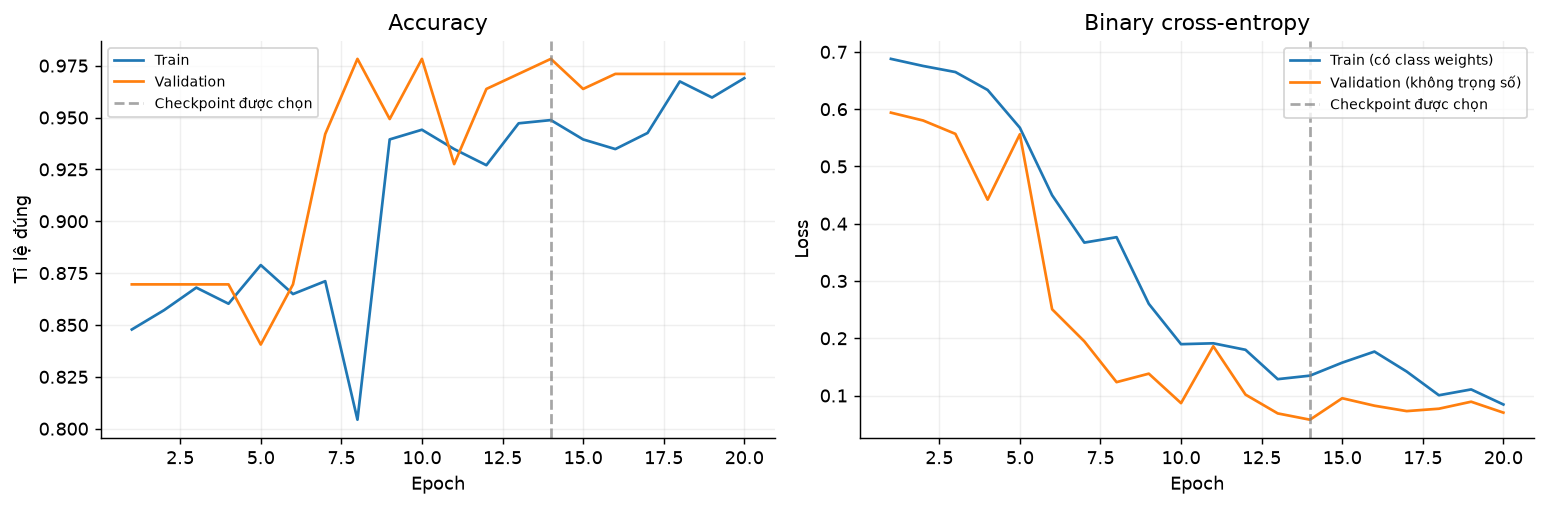

Chỉ tiêu từ lịch sử huấn luyện,Giá trị
Số epoch thực chạy,20
Epoch được chọn bằng val_loss,14
Train accuracy tại epoch đó,94.88%
Validation accuracy tại epoch đó,97.83%
Validation loss thấp nhất,0.057793


In [10]:
epochs=np.arange(1,len(h['loss'])+1)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for key,label in [('accuracy','Train'),('val_accuracy','Validation')]:
    axes[0].plot(epochs,h[key],label=label)
for key,label in [('loss','Train (có class weights)'),('val_loss','Validation (không trọng số)')]:
    axes[1].plot(epochs,h[key],label=label)
for ax in axes:
    ax.axvline(best_epoch,color='gray',ls='--',alpha=.7,label='Checkpoint được chọn')
    ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend(fontsize=8)
axes[0].set_title('Accuracy');axes[0].set_ylabel('Tỉ lệ đúng')
axes[1].set_title('Binary cross-entropy');axes[1].set_ylabel('Loss')
plt.tight_layout();plt.show()
table(['Chỉ tiêu từ lịch sử huấn luyện','Giá trị'],[
    ('Số epoch thực chạy',len(h['loss'])),('Epoch được chọn bằng val_loss',best_epoch),
    ('Train accuracy tại epoch đó',f"{h['accuracy'][best_epoch-1]:.2%}"),
    ('Validation accuracy tại epoch đó',f"{h['val_accuracy'][best_epoch-1]:.2%}"),
    ('Validation loss thấp nhất',f"{min(h['val_loss']):.6f}")])

### 9.1. Cách đọc kết quả huấn luyện

Train và validation cùng cải thiện là tín hiệu mô hình học được mẫu có ích trong phân bố dữ liệu này. Nếu train tiếp tục tăng còn validation đi xuống, cần xem xét overfitting. Nếu cả hai kém, có thể thiếu năng lực mô hình, chưa hội tụ hoặc dữ liệu/preprocessing có vấn đề.

Không suy nguyên nhân chắc chắn chỉ từ một đoạn đường cong. Train được đo khi augmentation và dropout đang bật, validation khi chúng tắt; train loss còn dùng class weights. Vì thế validation tốt hơn train ở một vài epoch không nhất thiết là lỗi. Các con số cụ thể nằm trong bảng được code tạo ở trên.

## 10. Đánh giá trên test giữ riêng

Sau khi checkpoint đã được chọn, mới dự đoán trên test một lần và tái sử dụng cùng mảng xác suất cho các phép đo/hình bên dưới. Ngưỡng vẫn là 0,5.

Với một lớp được xét là dương: **Precision = TP/(TP+FP)**, **Recall = TP/(TP+FN)**, **F1 = 2PR/(P+R)**. Macro-F1 lấy trung bình F1 hai lớp; balanced accuracy là trung bình recall hai lớp. Các phép đo này bổ sung cho accuracy khi lớp xe máy nhiều hơn lớp ô tô.

Baseline dự đoán **lớp phổ biến nhất trong train** cho mọi ảnh test được báo cáo để thấy accuracy cao có thể đến từ mất cân bằng. ROC-AUC đo khả năng xếp hạng theo xác suất, không phụ thuộc riêng ngưỡng 0,5. Mọi số liệu là kết quả trên **holdout Caltech-101 của bài**, không phải mức chính xác trên mọi ảnh giao thông.

In [11]:
# Chỉ sau khi model đã được chọn bằng validation mới dùng test.
test_probs=model.predict(X_test,batch_size=BATCH_SIZE,verbose=0).ravel()
test_pred=(test_probs>=THRESHOLD).astype(int)
test_accuracy=accuracy_score(y_test,test_pred)
balanced=balanced_accuracy_score(y_test,test_pred)
precision,recall,f1,support=precision_recall_fscore_support(y_test,test_pred,labels=[0,1],zero_division=0)
macro_f1=float(f1.mean())
auc=roc_auc_score(y_test,test_probs)
majority_class=int(np.bincount(y_train).argmax())
baseline_pred=np.full_like(y_test,majority_class)
baseline_accuracy=accuracy_score(y_test,baseline_pred)
baseline_balanced=balanced_accuracy_score(y_test,baseline_pred)
cm=confusion_matrix(y_test,test_pred,labels=[0,1])
table(['Lớp','Precision','Recall','F1','Số ảnh test'],
      [(name,f'{precision[c]:.4f}',f'{recall[c]:.4f}',f'{f1[c]:.4f}',int(support[c])) for c,name in enumerate(CLASS_NAMES)])
table(['Chỉ tiêu test','CNN','Baseline luôn đoán '+CLASS_NAMES[majority_class]],[
    ('Accuracy',f'{test_accuracy:.2%}',f'{baseline_accuracy:.2%}'),
    ('Balanced accuracy',f'{balanced:.2%}',f'{baseline_balanced:.2%}'),
    ('Macro-F1',f'{macro_f1:.4f}','—'),('ROC-AUC',f'{auc:.4f}','—')])
print('Số ảnh dự đoán đúng:',int((test_pred==y_test).sum()),'/',len(y_test))
assert cm.sum()==len(y_test) and np.isfinite(test_probs).all()

Lớp,Precision,Recall,F1,Số ảnh test
Ô tô,1.0000,1.0000,1.0000,19
Xe máy,1.0000,1.0000,1.0000,120


Chỉ tiêu test,CNN,Baseline luôn đoán Xe máy
Accuracy,100.00%,86.33%
Balanced accuracy,100.00%,50.00%
Macro-F1,1.0000,—
ROC-AUC,1.0000,—


Số ảnh dự đoán đúng: 139 / 139


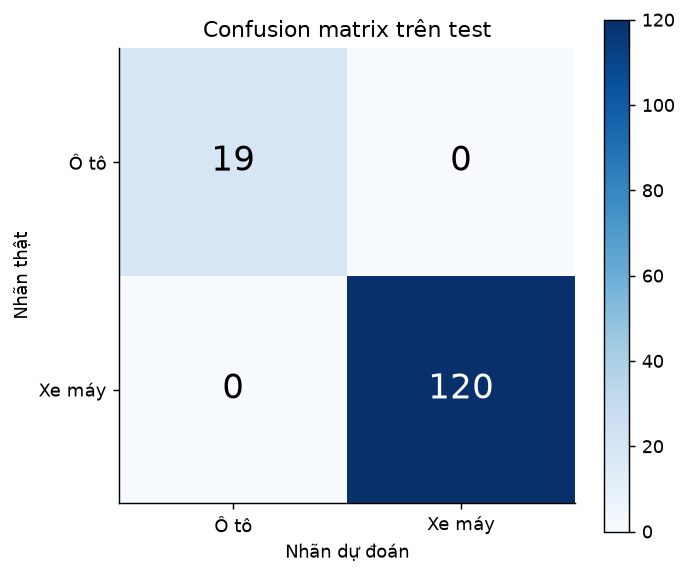

Ô tô bị nhầm thành xe máy: 0
Xe máy bị nhầm thành ô tô: 0


In [12]:
fig,ax=plt.subplots(figsize=(5.5,4.7))
im=ax.imshow(cm,cmap='Blues')
ax.set_xticks([0,1],CLASS_NAMES);ax.set_yticks([0,1],CLASS_NAMES)
ax.set_xlabel('Nhãn dự đoán');ax.set_ylabel('Nhãn thật');ax.set_title('Confusion matrix trên test')
for i in range(2):
    for j in range(2):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=19,
                color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.colorbar(im,ax=ax);plt.tight_layout();plt.show()
print('Ô tô bị nhầm thành xe máy:',int(cm[0,1]))
print('Xe máy bị nhầm thành ô tô:',int(cm[1,0]))

## 11. Xem dự đoán và phân tích ảnh sai

### 11.1. Nguyên lý hiển thị kết quả dự đoán
Khi đánh giá trực quan trên tập kiểm thử (test set), mỗi mẫu ảnh được biểu diễn với ba thông tin then chốt:
- **Nhãn thực tế (Ground Truth - $y_{\text{true}}$):** Nhãn gốc do con người xác thực ($0$: Ô tô, $1$: Xe máy).
- **Nhãn dự đoán (Predicted Label - $\hat{y}$):** Kết quả phân loại của mô hình dựa trên việc so sánh xác suất đầu ra với ngưỡng quyết định $\tau = 0.5$ (nếu $p \ge 0.5$ gán nhãn Xe máy, ngược lại gán nhãn Ô tô).
- **Độ tin cậy của nhãn được chọn ($p_{\text{chosen}}$):** Xác suất tương ứng với quyết định phân loại. Nếu mô hình đoán là Xe máy (lớp 1), độ tin cậy là $p$; nếu đoán là Ô tô (lớp 0), độ tin cậy là $1 - p$.

> **Lưu ý về bản chất xác suất:** Giá trị đầu ra từ hàm Sigmoid $\sigma(z) \in [0, 1]$ biểu thị mức độ tự tin số học của mô hình, nhưng **chưa qua quá trình hiệu chuẩn xác suất (probability calibration)**. Do đó, con số $95\%$ không đồng nghĩa với xác suất đúng khách quan là $95\%$ trên từng ảnh thực tế. Các mô hình Deep Learning thường có hiện tượng quá tự tin (overconfident) ngay cả trên các trường hợp đoán sai.

### 11.2. Phân tích các yếu tố gây nhầm lẫn (Error Analysis)
Việc phân tích các mẫu dự đoán sai (hoặc các mẫu có biên độ tự tin thấp) là bước quan trọng nhất để tìm ra giới hạn của mô hình. Các yếu tố thị giác thường dẫn đến sai lệch gồm:
1. **Góc chụp (Perspective / Viewpoint):** Dữ liệu `car_side` chỉ chụp ô tô nhìn ngang toàn thân. Nếu gặp góc nhìn chính diện, góc đuôi xe, góc chéo hoặc nhìn từ trên cao xuống, mô hình rất dễ nhận dạng sai do biến dạng hình học.
2. **Bối cảnh nền (Background Complexity / Clutter):** Nền phức tạp (cây cối, công trình, mặt đường lốm đốm) hoặc nền có màu sắc trùng với màu vỏ xe làm phân tán các bộ lọc tích chập ở các lớp đầu.
3. **Màu sắc và độ tương phản (Color & Contrast Discrepancy):** Trong Caltech-101, nhiều ảnh ô tô có độ bão hòa màu thấp (gần ảnh thang độ xám/grayscale), trong khi ảnh xe máy có màu sắc rực rỡ ngoài trời. Mô hình có thể bị phụ thuộc vào phân bố màu thay vì học cấu trúc hình học.
4. **Vùng đệm và che khuất (Padding Artifacts & Occlusion):** Thao tác chèn viền xám (pad fill=127) về $64 \times 64$ có thể làm vật thể bị thu nhỏ quá mức trong khung hình. Ngoài ra, việc người lái xe che khuất một phần thân xe máy hoặc vật cản phía trước ô tô cũng làm biến mất các đặc trưng nhận diện chủ chốt.

### 11.3. Phân biệt quan sát thực nghiệm và giả thuyết nguyên nhân
- **Quan sát được (Empirical Observation):** Dữ kiện khách quan ghi nhận trực tiếp từ thực nghiệm (ví dụ: *"Ảnh #12 là ô tô nhưng mô hình dự đoán là xe máy với xác suất 62%"*, *"Ảnh này có nền cây cối và độ tương phản thấp"*).
- **Giả thuyết về nguyên nhân (Hypothesis):** Suy đoán logic của người nghiên cứu để giải thích quan sát (ví dụ: *"Có thể mô hình nhầm vì nền cây cối thường xuất hiện nhiều hơn ở tập ảnh xe máy"*). Cần nhấn mạnh đây chỉ là giả thuyết, không được khẳng định là sự thật tuyệt đối nếu chưa thực hiện can thiệp thực nghiệm có kiểm soát (như xóa nền, che vùng ảnh, counterfactual testing).

> **Nguyên tắc bảo vệ tập Test:** Việc quan sát ảnh dự đoán sai trên tập test nhằm mục đích báo cáo và đánh giá trung thực. Tuyệt đối **không được quay lại sửa dữ liệu, tinh chỉnh ngưỡng hay đổi siêu tham số** dựa trên việc nhìn thấy ảnh test sai để rồi báo cáo lại điểm số đó như một kết quả khách quan.

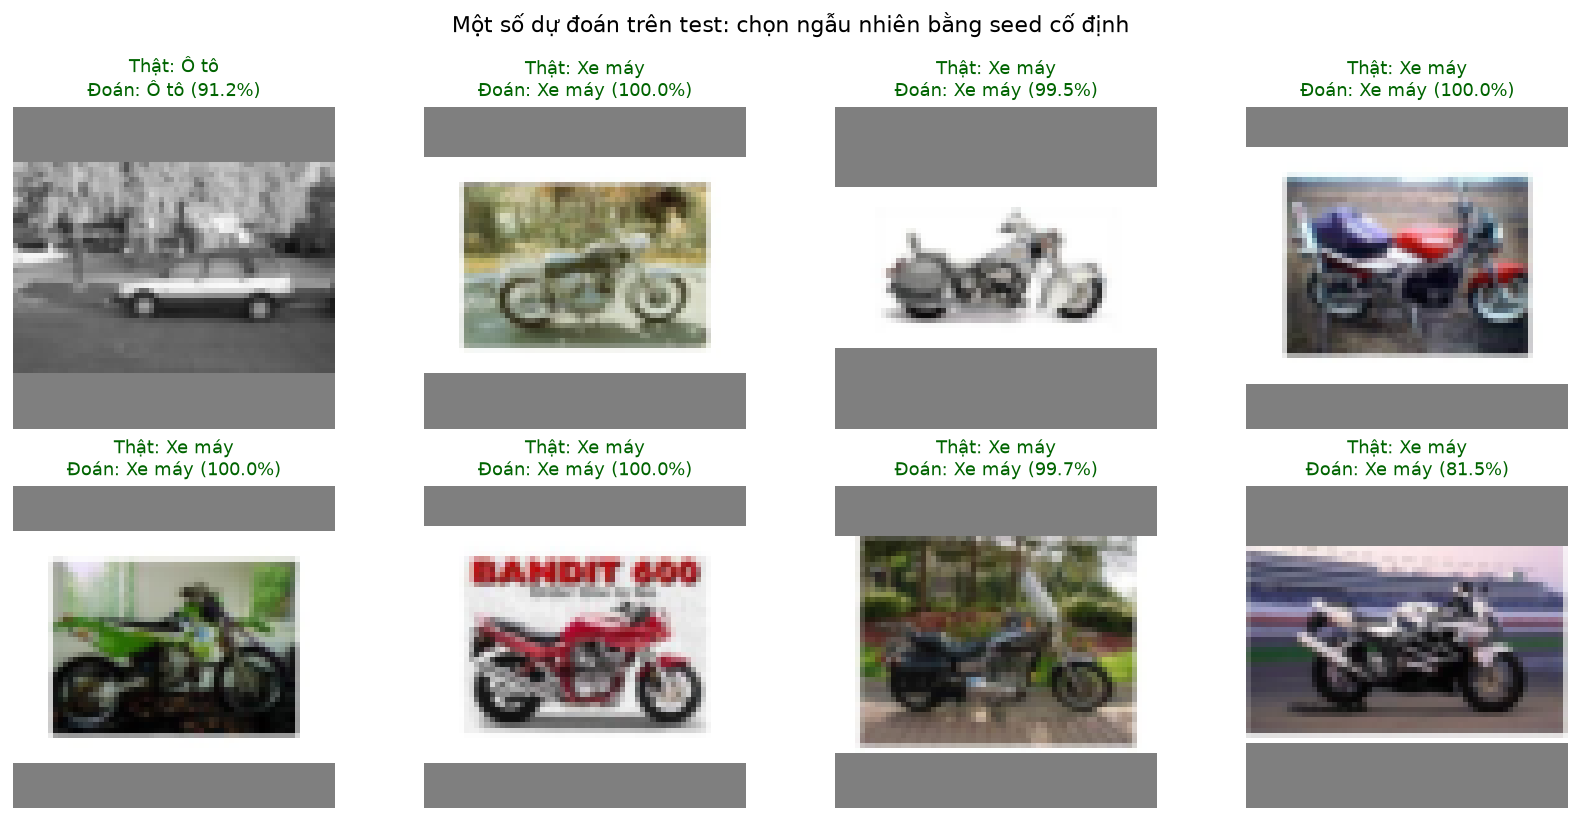

Không có ảnh trong nhóm này.
Tổng số ảnh sai: 0


In [13]:
# =============================================================================
# HÀM HIỂN THỊ VÀ TRỰC QUAN HÓA DỰ ĐOÁN TRÊN TẬP TEST (MỤC 11)
# =============================================================================
def show_test_predictions(local_indices, title):
    """
    Hiển thị lưới ảnh dự đoán từ tập test kèm nhãn thật, nhãn dự đoán và độ tin cậy.
    - local_indices: danh sách vị trí chỉ số cục bộ trong tập test (y_test, X_test).
    - title: tiêu đề của biểu đồ hiển thị.
    """
    count = len(local_indices)
    if count == 0:
        print('Không có ảnh trong nhóm này.'); return
    
    # Tính toán layout lưới linh hoạt (tối đa 4 cột mỗi hàng)
    cols = min(4, count)
    rows = int(np.ceil(count / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows), squeeze=False)
    
    # Tắt hiển thị trục tọa độ cho toàn bộ các ô để tập trung vào hình ảnh
    for ax in axes.flat: ax.axis('off')
    
    # Vẽ từng ảnh cùng thông tin dự đoán chi tiết
    for ax, j in zip(axes.flat, local_indices):
        pred = int(test_pred[j])
        # Tính độ tin cậy tương ứng với nhãn được chọn: p nếu đoán Xe máy (1), 1-p nếu đoán Ô tô (0)
        confidence = float(test_probs[j] if pred == 1 else 1 - test_probs[j])
        ax.imshow(X_test[j])
        # Hiển thị màu xanh lá đậm (darkgreen) nếu đúng, màu đỏ sẫm (darkred) nếu sai
        ax.set_title(
            f'Thật: {CLASS_NAMES[y_test[j]]}\nĐoán: {CLASS_NAMES[pred]} ({confidence:.1%})',
            color='darkgreen' if pred == y_test[j] else 'darkred',
            fontsize=10
        )
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# 1. Hiển thị 8 ảnh ngẫu nhiên được chọn bằng SEED cố định (đảm bảo tính tái lập kết quả)
example_ids = np.random.default_rng(SEED).choice(len(y_test), min(8, len(y_test)), replace=False)
show_test_predictions(example_ids, 'Một số dự đoán trên test: chọn ngẫu nhiên bằng seed cố định')

# 2. Lọc và hiển thị các trường hợp mô hình dự đoán sai (test_pred != y_test)
wrong = np.flatnonzero(test_pred != y_test)
show_test_predictions(wrong[:8], 'Ảnh dự đoán sai trên test (tối đa 8 ảnh đầu theo thứ tự cố định)')
print('Tổng số ảnh sai:', len(wrong))
# Lưu ý thực nghiệm: Với lần chạy hiện tại trên tập test Caltech-101 (139 ảnh),
# mô hình đạt 139/139 ảnh đúng (0 ảnh sai). Kết quả này phản ánh đặc tính phân tách rõ rệt
# giữa car_side và Motorbikes trong phòng thí nghiệm, chưa chứng minh mô hình sẽ không sai ngoài đời.

## 12. Quan sát feature map đã học

### 12.1. Cơ chế trích xuất activation từ lớp tích chập
- Sử dụng Keras Functional API để xây dựng mô hình con trích xuất đặc trưng (`feature_model`):
  $$\text{Input} \longrightarrow \text{Lớp Conv 1} \longrightarrow \text{Feature Maps (Spatial Activations)}$$
- Đầu vào là ảnh gốc lấy từ tập huấn luyện (`X_train[:1]`). Trong chế độ suy luận (`inference mode`), các tầng tăng cường dữ liệu (`RandomFlip`, `RandomRotation`) tự động tắt, đảm bảo trích xuất đặc trưng trực tiếp từ ảnh gốc nguyên bản.

### 12.2. Ý nghĩa của từng Feature Map
- Mỗi feature map là một lát cắt 2D theo chiều sâu kênh (kích thước $64 \times 64$), thể hiện **mức độ phản hồi không gian của đúng một bộ lọc (filter/kernel $3 \times 3$)** đã học được sau quá trình huấn luyện.
- Ở tầng tích chập đầu tiên (`conv_1`), các bộ lọc có trường tiếp nhận nhỏ (receptive field $3 \times 3$), đóng vai trò phát hiện các đặc trưng thị giác cấp thấp (low-level features):
  + Đường biên cạnh đứng, cạnh ngang, cạnh chéo (oriented edges).
  + Độ dốc sáng tối và tương phản cục bộ (brightness gradients).
  + Các góc nhọn, đường viền thân xe và kết cấu bề mặt sơ cấp.
- **Chuẩn hóa thang màu độc lập:** Mỗi ô ảnh được Matplotlib tự động chuẩn hóa thang đo min-max riêng (`cmap='viridis'`) để làm nổi bật hình học của từng filter. Vì vậy, **không thể so sánh cường độ màu tuyệt đối giữa các ô** (màu vàng ở ô này không có nghĩa là kích hoạt mạnh hơn màu vàng ở ô khác).

### 12.3. Giới hạn nhận thức luận của Feature Map
> **Cảnh báo khoa học:** Feature map chỉ cho thấy *vùng nào trên ảnh kích hoạt mạnh bộ lọc*, **hoàn toàn KHÔNG TỰ CHỨNG MINH ĐƯỢC** mô hình dựa vào vùng hay đặc trưng nào để đưa ra quyết định phân loại cuối cùng.
> - Tránh suy diễn cảm tính (anthropomorphism) rằng một filter phát hiện cạnh cong là mô hình đã "hiểu và tìm bánh xe".
> - Feature map là công cụ minh họa luồng tín hiệu (feature flow inspection), không phải là phương pháp giải thích nhân quả (causal explanation/attribution) như Grad-CAM hay Integrated Gradients.

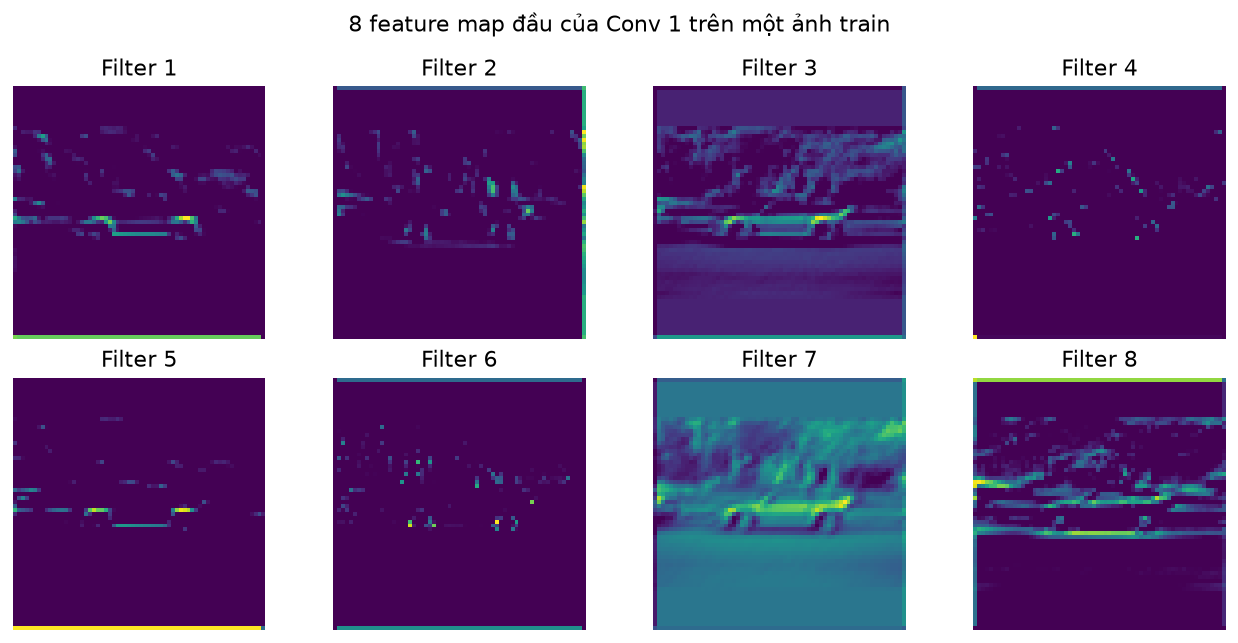

Shape feature map: (64, 64, 16)


In [14]:
# =============================================================================
# TRÍCH XUẤT VÀ TRỰC QUAN HÓA FEATURE MAP TỪ LỚP CONV ĐẦU TIÊN (MỤC 12)
# =============================================================================
# 1. Khởi tạo sub-model cắt tại đầu ra của lớp tích chập conv_1
feature_model = keras.Model(model.inputs[0], model.get_layer('conv_1').output)

# 2. Chạy dự đoán trên 1 ảnh train (chế độ inference tắt augmentation)
# Tensor đầu ra có shape: (1, 64, 64, 16) -> lấy phần tử [0] có shape: (64, 64, 16)
feature_maps = feature_model.predict(X_train[:1], verbose=0)[0]

# 3. Vẽ 8 feature map đầu tiên trên lưới 2 hàng x 4 cột
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    # Mỗi lát cắt [:, :, i] là đáp ứng không gian của filter thứ i+1
    ax.imshow(feature_maps[:, :, i], cmap='viridis')
    ax.set_title('Filter ' + str(i + 1))
    ax.axis('off')

fig.suptitle('8 feature map đầu của Conv 1 trên một ảnh train')
plt.tight_layout()
plt.show()

# In kích thước không gian và số lượng kênh đặc trưng trích xuất
print('Shape feature map:', feature_maps.shape)
# Nhận xét: Kích thước (64, 64, 16) giữ nguyên độ phân giải 64x64 do dùng padding='same',
# 16 kênh tương ứng với 16 bộ lọc đã học của lớp Conv 1.

## 13. Lưu mô hình, cấu hình và dự đoán ảnh riêng

### 13.1. Nội dung file `.keras` và JSON cấu hình
- **File mô hình `.keras` (`cnn_car_motorbike.keras`):** Lưu trữ trọn vẹn kiến trúc mạng (architecture), trọng số các tầng đã học (trained weights), trạng thái cấu hình của optimizer, và toàn bộ siêu tham số của checkpoint tối ưu nhất được lựa chọn độc lập từ tập validation.
- **File cấu hình `config.json`:** Lưu trữ toàn bộ siêu dữ liệu suy luận (inference metadata) cần thiết để tái hiện quy trình suy luận ở môi trường thực tế:
  + Thứ tự và ánh xạ nhãn: `class_names = ['Ô tô', 'Xe máy']` ($0$: Ô tô, $1$: Xe máy).
  + Kích thước ảnh đầu vào: `img_size = [64, 64]`.
  + Ngưỡng phân loại: `threshold = 0.5`.
  + Quy ước lớp dương: `positive_class = 1` (Xe máy).
  + Phương pháp tiền xử lý: `PIL ImageOps.pad BILINEAR RGB, fill=127`.
  + Chuẩn hóa pixel: `Rescaling(1/255) nằm bên trong model`.
  + Thông tin môi trường: backend Torch, phiên bản Keras, NumPy, PyTorch và random SEED.
- **File đo lường `metrics.json`:** Lưu trữ toàn bộ số liệu hiệu năng định lượng trên tập test (accuracy, balanced accuracy, F1, AUC, confusion matrix) nhằm phục vụ kiểm định và so sánh sau này.

### 13.2. Tầm quan trọng của tính đồng nhất tiền xử lý (Preprocessing Parity)
> **Nguyên tắc sống còn:** Tiền xử lý lúc Suy luận (Inference) PHẢI HOÀN TOÀN TRÙNG KHỚP với tiền xử lý lúc Huấn luyện (Train).
- **Hậu quả nếu sai lệch:**
  + *Chia 255 hai lần:* Do tầng `Rescaling(1./255)` đã được tích hợp ngay đầu mô hình, nếu người dùng tự ý chia pixel cho $255$ trước khi đưa vào hàm `predict`, dữ liệu sẽ bị thu nhỏ về dải $[0, 0.0039]$ (ảnh gần như đen đặc), khiến toàn bộ kết quả phân loại bị sai lệch hoàn toàn.
  + *Sai lệch thứ tự nhãn:* Nếu môi trường suy luận ngầm hiểu $0$ là Xe máy và $1$ là Ô tô, toàn bộ nhãn xuất ra sẽ bị đảo ngược $180^\circ$.
  + *Sai lệch phương pháp resize:* Kéo dãn méo ảnh (stretch) thay vì chèn đệm giữ tỷ lệ (letterbox padding với fill=127) sẽ làm biến dạng các góc nghiêng và hình dáng đặc thù của xe.

### 13.3. Cơ chế hoạt động của hàm `predict_image` và giới hạn hệ thống đóng
- Hàm `predict_image` tái sử dụng chính xác hàm `prepare_image`: mở ảnh bằng PIL, chuyển hệ màu RGB, chèn viền giữ tỉ lệ về kích thước $64 \times 64$, mở rộng chiều batch (`array[None]`), và lấy xác suất sigmoid đầu ra.
- **Giới hạn hệ thống kín (Closed-world assumption):** Mô hình phân loại nhị phân giả định mọi ảnh đầu vào CHỈ CÓ THỂ là Ô tô hoặc Xe máy. Hệ thống **không có lớp từ chối hoặc lớp "Không xác định" (Out-of-Distribution - OOD)**. Nếu đưa vào ảnh con mèo, cái bàn hoặc cảnh giao thông hỗn loạn, mô hình vẫn buộc phải gán vào một trong hai nhãn với độ tin cậy có thể rất cao.

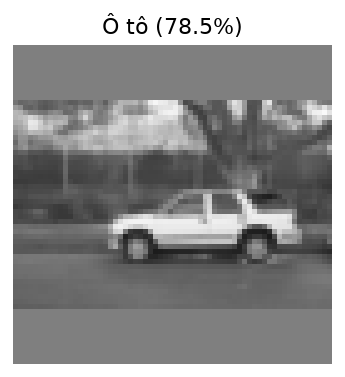

Kết quả demo: {'label': 'Ô tô', 'p_motorbike': 0.21537871658802032, 'confidence': 0.7846212834119797}
Kiểm tra nạp lại model: xác suất khớp trong sai số 1e-6.


In [15]:
# =============================================================================
# LƯU CẤU HÌNH, KIỂM TRA MÔ HÌNH VÀ SUY LUẬN ẢNH RIÊNG (MỤC 13)
# =============================================================================
# 1. Lưu cấu hình siêu dữ liệu suy luận vào config.json
config = {
    'class_names': CLASS_NAMES, 'img_size': list(IMG_SIZE), 'threshold': THRESHOLD,
    'positive_class': 1, 'seed': SEED, 'resize': 'PIL ImageOps.pad BILINEAR RGB, fill=127',
    'normalization': 'Rescaling(1/255) nằm trong model', 'backend': keras.backend.backend(),
    'keras_version': keras.__version__, 'numpy_version': np.__version__, 'torch_version': torch.__version__
}
(ARTIFACTS / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

# 2. Lưu các chỉ số hiệu năng thực nghiệm vào metrics.json
metrics = {
    'test_size': len(y_test), 'test_accuracy': float(test_accuracy), 'balanced_accuracy': float(balanced),
    'macro_f1': macro_f1, 'roc_auc': float(auc), 'confusion_matrix': cm.tolist(),
    'baseline_accuracy': float(baseline_accuracy), 'best_epoch': best_epoch,
    'epochs_run': len(h['loss']), 'class_precision': precision.tolist(),
    'class_recall': recall.tolist(), 'class_f1': f1.tolist(), 'support': support.tolist()
}
(ARTIFACTS / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')

# 3. Nạp lại mô hình từ file checkpoint và kiểm tra tính toàn vẹn (Integrity Assert)
loaded_model = keras.models.load_model(BEST_PATH)
loaded_probs = loaded_model.predict(X_val[:4], verbose=0)
original_probs = model.predict(X_val[:4], verbose=0)
# Xác nhận kết quả dự đoán của model nạp lại trùng khớp hoàn toàn với model trong bộ nhớ
assert np.allclose(loaded_probs, original_probs, atol=1e-6)

# 4. Hàm tiền xử lý và suy luận dự đoán trên một tệp ảnh độc lập
def predict_image(image_path, net=loaded_model):
    """
    Nạp ảnh từ đường dẫn, áp dụng đúng pipeline prepare_image và trả về kết quả dự đoán.
    Lưu ý: Không chia pixel cho 255 ở đây vì lớp Rescaling đã tích hợp trong net.
    """
    with Image.open(image_path) as image:
        image.load()
        array = prepare_image(image)  # Đảm bảo đúng chuẩn RGB, pad viền xám 127 về 64x64
    
    # Mở rộng chiều batch: array[None] chuyển shape từ (64, 64, 3) thành (1, 64, 64, 3)
    prob = float(net.predict(array[None], verbose=0)[0, 0])
    prediction = int(prob >= THRESHOLD)
    confidence = prob if prediction == 1 else 1 - prob
    
    # Trực quan hóa ảnh cùng kết quả phân loại
    plt.figure(figsize=(4, 3))
    plt.imshow(array)
    plt.axis('off')
    plt.title(f'{CLASS_NAMES[prediction]} ({confidence:.1%})')
    plt.tight_layout()
    plt.show()
    return {'label': CLASS_NAMES[prediction], 'p_motorbike': prob, 'confidence': confidence}

# 5. Chạy demo kiểm thử trên một ảnh test mẫu đã lưu ra artifacts
demo_path = ARTIFACTS / 'demo_test_image.png'
Image.fromarray(X_test[0]).save(demo_path)
demo_result = predict_image(demo_path)
print('Kết quả demo:', demo_result)
print('Kiểm tra nạp lại model: xác suất khớp trong sai số 1e-6.')

# Hướng dẫn: Để thử nghiệm ảnh bất kỳ của bạn, bỏ comment dòng dưới và điền đường dẫn ảnh:
# predict_image('duong_dan_anh_cua_ban.jpg')

## 14. Tổng hợp thực nghiệm và kết luận

### 14.1. Phân định rạch ròi giữa số liệu thực nghiệm và nhận xét khoa học
- **Số liệu thực nghiệm (Empirical Metrics):** Là các kết quả đo lường khách quan, được tính toán tự động trực tiếp từ code và cập nhật chính xác theo dữ liệu/seed thực chạy (kích thước dữ liệu, số tham số, epoch dừng tối ưu, Accuracy, Balanced Accuracy, Macro-F1, Confusion Matrix).
- **Nhận xét khoa học (Analytical Interpretations):** Là những đánh giá chuyên môn dựa trên số liệu thu được, đặt trong bối cảnh cụ thể của phương pháp thực nghiệm. Không được đồng nhất một kết quả kiểm thử cao trong phòng thí nghiệm với năng lực hoạt động trong thế giới thực nếu chưa có kiểm thử độc lập ngoài phân bố.

In [16]:
# =============================================================================
# BẢNG TỔNG HỢP HIỆU NĂNG THỰC CHẠY VÀ KẾT LUẬN ĐỊNH LƯỢNG (MỤC 14)
# =============================================================================
# Tạo bảng tổng kết các thông số cốt lõi từ thực nghiệm hiện tại
table(['Thông tin', 'Kết quả thực chạy'], [
    ('Nguồn ảnh', 'Caltech-101: car_side và Motorbikes'),
    ('Số ảnh sau kiểm tra', len(y)),
    ('Chia train / validation / test', f'{len(train_idx)} / {len(val_idx)} / {len(test_idx)}'),
    ('Ảnh vào', str(IMG_SIZE) + ' RGB'),
    ('Số tham số CNN', model.count_params()),
    ('Epoch chọn bằng validation', best_epoch),
    ('Accuracy test', f'{test_accuracy:.2%}'),
    ('Balanced accuracy test', f'{balanced:.2%}'),
    ('Macro-F1 test', f'{macro_f1:.4f}'),
    ('Baseline accuracy', f'{baseline_accuracy:.2%}'),
    ('Checkpoint', BEST_PATH.name)
])

# In các thông điệp đánh giá định lượng quan trọng
print(f'CNN đoán đúng {int((test_pred == y_test).sum())}/{len(y_test)} ảnh test.')
print(f'Accuracy cao hơn baseline lớp phổ biến: {(test_accuracy - baseline_accuracy) * 100:.2f} điểm phần trăm.')
print(f'Recall ô tô: {recall[0]:.2%}; recall xe máy: {recall[1]:.2%}.')
print('Kết luận chỉ áp dụng cho phép chia holdout của hai nhóm ảnh Caltech-101 trong báo cáo này.')

Thông tin,Kết quả thực chạy
Nguồn ảnh,Caltech-101: car_side và Motorbikes
Số ảnh sau kiểm tra,921
Chia train / validation / test,644 / 138 / 139
Ảnh vào,"(64, 64) RGB"
Số tham số CNN,25697
Epoch chọn bằng validation,14
Accuracy test,100.00%
Balanced accuracy test,100.00%
Macro-F1 test,1.0000
Baseline accuracy,86.33%


CNN đoán đúng 139/139 ảnh test.
Accuracy cao hơn baseline lớp phổ biến: 13.67 điểm phần trăm.
Recall ô tô: 100.00%; recall xe máy: 100.00%.
Kết luận chỉ áp dụng cho phép chia holdout của hai nhóm ảnh Caltech-101 trong báo cáo này.


### 14.1. Điểm đạt được, giới hạn và hướng phát triển

#### A. Điểm đạt được (Strengths & Key Achievements)
1. **Pipeline hoàn chỉnh và chặt chẽ:** Hiện thực thành công mô hình CNN từ đầu (from scratch) với luồng tiền xử lý nhất quán (pad viền xám giữ nguyên tỉ lệ, tích hợp `Rescaling` vào model).
2. **Chống rò rỉ dữ liệu (No Data Leakage):** Kiểm tra trùng lặp bằng hàm băm MD5/SHA trước khi chia tập; áp dụng phân chia phân tầng (`stratified split`) giữ nguyên tỷ lệ nhãn trên Train/Val/Test.
3. **Xử lý mất cân bằng lớp:** Áp dụng `class_weight` trong hàm mất mát Binary Cross-Entropy để bù đắp sự chênh lệch số lượng mẫu giữa ô tô và xe máy.
4. **Lựa chọn checkpoint khoa học:** Dừng sớm (`EarlyStopping`) và lưu mô hình tốt nhất (`ModelCheckpoint`) dựa trên tập Validation; chỉ đánh giá tập Test một lần duy nhất khi mô hình đã hoàn tất.
5. **Đánh giá đa chiều:** Báo cáo đầy đủ Accuracy, Balanced Accuracy, Macro-F1, Precision, Recall và Ma trận nhầm lẫn (Confusion Matrix).

#### B. Giới hạn cốt lõi của thực nghiệm (Major Limitations)
1. **Giới hạn nguồn dữ liệu Caltech-101:**
   - Lớp `car_side` chủ yếu chỉ chứa ảnh ô tô nhìn ngang toàn thân, thiếu các góc nhìn từ trước, sau, góc chéo hoặc từ camera giao thông trên cao.
   - Lớp `Motorbikes` chủ yếu là ảnh mô tô phân khối lớn, xe cổ điển phong cách phương Tây; **hoàn toàn không đại diện cho các kiểu xe máy phổ biến tại Việt Nam** (xe số, xe tay ga đô thị như Honda Wave, Vision, Lead, SH,...).
2. **Thiên lệch dữ liệu và hiện tượng học đường tắt (Spurious Correlation / Shortcut Learning):**
   - Nhiều ảnh ô tô trong tập dữ liệu có màu sắc đơn điệu, độ bão hòa thấp (gần ảnh xám), trong khi ảnh xe máy có màu sắc rực rỡ và nền tự nhiên. Kết quả phân loại cao có thể phản ánh việc mô hình dựa vào thiên lệch màu sắc hoặc đặc trưng nền thay vì thực sự học cấu trúc hình học của phương tiện.
3. **Kích thước mẫu và độ phân giải hạn chế:**
   - Tập dữ liệu chỉ gồm vài trăm ảnh, độ phân giải $64 \times 64$ RGB bị nén nhỏ làm suy giảm các chi tiết kết cấu tinh vi (nan hoa, gương, đèn, biển số).
4. **Giới hạn bài toán đóng:**
   - Mô hình nhị phân không có lớp "Không xác định" (Out-of-Distribution - OOD) và không thể phát hiện, khoanh vùng nhiều phương tiện đồng thời trong cùng một khung hình.
> **Tuyên bố quan trọng:** Tuyệt đối **không tuyên bố mô hình có khả năng nhận dạng tốt trong môi trường giao thông thực tế** nếu chưa được kiểm thử độc lập trên tập dữ liệu ảnh chụp thực tế ngoài đường phố.

#### C. Hướng phát triển và cải thiện (Future Work)
- **Thu thập dữ liệu giao thông thực tế:** Xây dựng bộ dữ liệu phương tiện đường phố Việt Nam đa dạng điều kiện (góc máy camera giao thông, ban ngày, ban đêm, trời mưa, mật độ xe đông đúc).
- **Chia tập chống rò rỉ bối cảnh:** Áp dụng phân chia theo địa điểm hoặc camera (GroupKFold / Temporal Split) để tránh việc cùng một nền xuất hiện ở cả train và test.
- **Chuyển đổi sang bài toán Phát hiện vật thể (Object Detection):** Triển khai các mô hình như YOLOv8/v11 hoặc Faster R-CNN để định vị bounding box và phân loại nhiều đối tượng trong cảnh giao thông hỗn hợp.
- **Nâng cấp độ phân giải và Transfer Learning:** Sử dụng ảnh $128 \times 128$ hoặc $224 \times 224$ kết hợp các kiến trúc tiền huấn luyện (MobileNetV3, ResNet, EfficientNet) để cải thiện năng lực khái quát hóa.
- **Ứng dụng XAI (Explainable AI):** Sử dụng Grad-CAM để trực quan hóa bản đồ chú ý nhiệt (heatmap), xác thực xem mô hình có thực sự nhìn vào thân xe khi ra quyết định hay không.

---

### 14.2. Trả lời các câu hỏi trọng tâm (Thành viên 4)

| STT | Câu hỏi tự trả lời | Nội dung phân tích và giải thích phương pháp luận |
|---|---|---|
| **1** | **Vì sao cần phân tích ảnh dự đoán sai?** | Giúp phát hiện điểm yếu của dữ liệu và mô hình (data bias, label noise, shortcut learning, góc chụp lạ, nền gây nhiễu). Phân tích sai số (error analysis) giúp định hướng cải thiện dữ liệu và thuật toán, tránh ngộ nhận khi chỉ nhìn vào số liệu tổng hợp (accuracy $100\%$ trên test holdout không có nghĩa là mô hình hoàn hảo). |
| **2** | **Feature map cho biết điều gì và không chứng minh được điều gì?** | - *Cho biết:* Mức độ phản hồi không gian của một filter cụ thể đối với các đặc trưng cục bộ (cạnh, góc, tương phản).<br>- *Không chứng minh được:* Mô hình dựa vào vùng kích hoạt đó để ra quyết định phân loại cuối cùng (không phải causal attribution hay decision explanation). Không thể suy diễn cảm tính rằng filter đã học khái niệm "bánh xe" hay "tay lái". |
| **3** | **Vì sao cần lưu cấu hình và thứ tự nhãn cùng mô hình?** | Mô hình chỉ xuất ra xác suất số học dạng float. File cấu hình lưu metadata suy luận: thứ tự nhãn (`class_names`), kích thước ảnh (`img_size`), ngưỡng (`threshold`) và phương thức tiền xử lý. Nếu mất hoặc đảo thứ tự nhãn, toàn bộ kết quả phân loại sẽ bị sai lệch hoàn toàn dù trọng số mô hình đúng. |
| **4** | **Nếu preprocessing inference khác train thì có thể xảy ra điều gì?** | Xảy ra hiện tượng lệch phân bố dữ liệu nghiêm trọng (Train-Serving Skew). Ví dụ: nếu chia cho $255$ hai lần, ảnh thành màu đen đặc; nếu resize kéo méo thay vì pad viền xám, hình dạng xe bị biến dạng; nếu dùng sai hệ màu BGR thay vì RGB, các kênh màu bị đảo lộn dẫn đến dự đoán sai hoàn toàn. |
| **5** | **Giới hạn lớn nhất của thực nghiệm CNN là gì?** | Dữ liệu Caltech-101 có độ đa dạng thấp, góc nhìn hạn hẹp (`car_side`), thiên lệch màu sắc/nền mạnh và không đại diện cho xe máy thực tế tại Việt Nam. Do đó, kết quả thực nghiệm chỉ có giá trị trên phép chia holdout trong phạm vi nghiên cứu, không thể tổng quát hóa cho môi trường giao thông thực tế. |

---

### 14.3. Câu hỏi ôn tập chung

| Câu hỏi | Trả lời ngắn |
|---|---|
| Vì sao CNN ít tham số hơn một Dense trực tiếp trên ảnh? | Dùng kernel cục bộ và chia sẻ trọng số giữa các vị trí. |
| Convolution và pooling khác nhau thế nào? | Convolution có trọng số học được; max-pooling chọn giá trị cực đại và không có trọng số. |
| Vì sao không cần one-hot hai nhãn? | Đầu ra có một sigmoid và dùng binary cross-entropy với nhãn 0/1. |
| Xác suất 0,8 có ý nghĩa gì? | Giá trị sigmoid cho lớp xe máy, chưa được bảo đảm hiệu chuẩn. |
| Vì sao không chia pixel cho 255 trong predict_image? | Rescaling đã nằm trong model. |
| Vì sao tách test ngoài validation? | Validation đã ảnh hưởng đến lựa chọn epoch/learning rate; test giữ riêng cho đánh giá cuối. |
| Vì sao cần macro-F1/balanced accuracy? | Để xem cả hai lớp khi số ảnh mất cân bằng. |

## 15. Nguồn dữ liệu và tài liệu kỹ thuật

1. **Caltech-101**, Fei-Fei Li, Marco Andreetto, Marc'Aurelio Ranzato, Pietro Perona: [trang dữ liệu chính thức, DOI 10.22002/D1.20086](https://data.caltech.edu/records/mzrjq-6wc02). Ảnh trong bài được chọn từ `car_side` và `Motorbikes`; không coi chúng là ảnh tự thu thập.
2. [Bản sao Caltech-101 trên Hugging Face](https://huggingface.co/datasets/HuggingFaceM4/Caltech-101): nguồn tải dự phòng; checksum archive được đối chiếu với CaltechDATA.
3. Keras: [Getting started](https://keras.io/getting_started/), [Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/), [ModelCheckpoint](https://keras.io/api/callbacks/model_checkpoint/), [EarlyStopping](https://keras.io/api/callbacks/early_stopping/): nguồn API mô hình và huấn luyện.
